# Split protocols, feature selection, and BCE models on SWaT

`python src/experiment.py` runs every detector on one chronological split;
this notebook asks whether that split, the cleaning, and the training loop do
the models justice:

1. **Where do the attacks land?** The chronological split puts one 10-hour
   attack (78% of all attack rows) in validation and leaves train with 9
   short attacks. `stratified_episode_split` assigns whole incidents,
   stratified by the stage they target, with purged boundaries.
2. **Is the data clean enough for unsupervised models?** Six chemical
   analysers drift by several standard deviations between the normal week
   and the attack days.
3. **Does Pearson-based feature selection help?** Chosen on validation only.
4. **Do the BCE models (logistic regression, MLP, CNN) and AdaBoost hold up**,
   and do the training-loop changes help?

Everything is computed through `src/`; nothing is re-implemented here.

In [1]:
import os
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"

import sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
from IPython.display import Image, display

from config import DATA_PROCESSED, RESULTS
from data import load_swat, chronological_split, stratified_episode_split
from features import pearson_select, drift_report, subset
import visualize as viz

FIG = RESULTS / "figures"
FIG.mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 160)

## Load once, cache locally

`load_swat()` parses ~250 MB of xlsx (about 4 minutes). The parsed frame is
cached under `data/processed/` (gitignored, same iTrust terms as `data/raw/`).
Delete the pickle to force a re-parse.

In [2]:
cache = DATA_PROCESSED / "swat_loaded.pkl"
if cache.exists():
    df_raw = pd.read_pickle(cache)
else:
    df_raw = load_swat()
    df_raw.to_pickle(cache)
print(f"{len(df_raw):,} rows, {df_raw.shape[1] - 1} features, attack rate {df_raw.label.mean():.4f}")

925,119 rows, 51 features, attack rate 0.0590


## 1. Data quality: constant sensors and drift

Six sensors never change anywhere in the data and four more are constant on
the chronological training window. A constant-in-train sensor carries no
information for a model, and any change at test time is pure shift.

`drift_report` compares each sensor's **normal-row** mean in validation with
training, in training standard deviations. Bars past ±1 mean the plant's
normal operating point itself moved.

swat-stratified: 22 incidents, 11,400 rows purged at 19 boundaries
stage  P1  P2  P3  P4  P5
row_0                    
test    1   1   2   0   2
train   1   1   4   1   3
val     1   0   2   1   2

constant everywhere:    ['P202', 'P401', 'P404', 'P502', 'P601', 'P603']
constant in chrono train: ['P201', 'P202', 'P204', 'P206', 'P401', 'P403', 'P404', 'P502', 'P601', 'P603']
saved -> /Users/santhosh/Desktop/urex-ics/results/figures/swat-drift-chrono.png


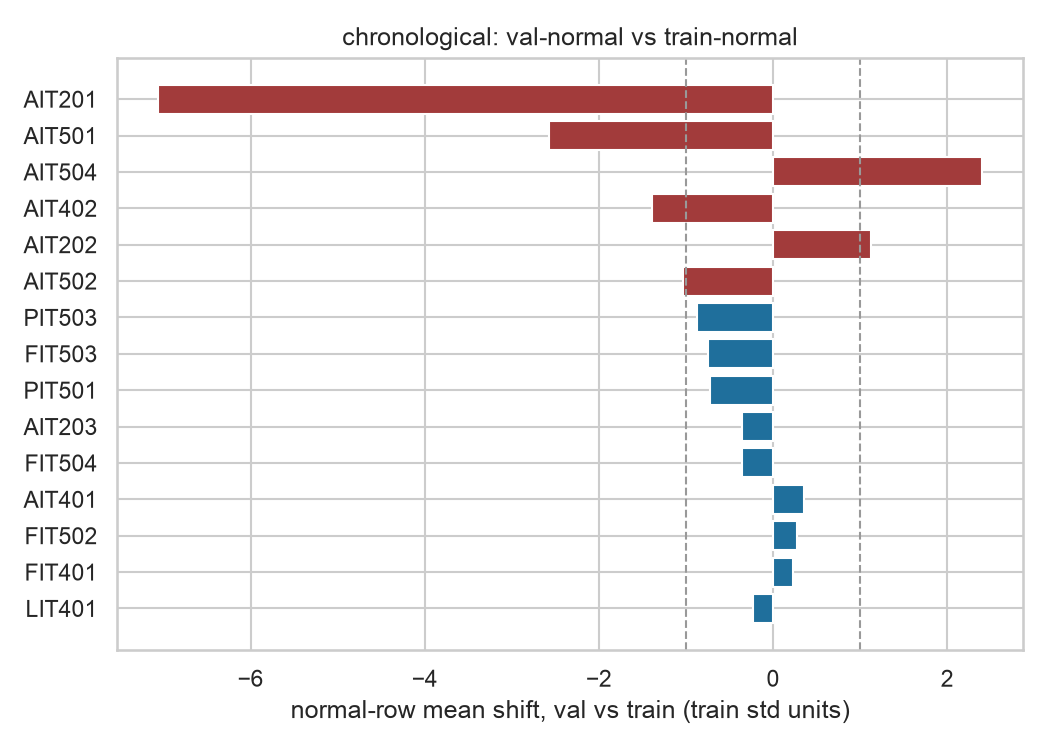

,feature,val_normal_shift_z,val_std_ratio,constant_in_train_normal,drifting
0,AIT201,-7.057215,4.713776,False,True
1,AIT501,-2.569054,1.665937,False,True
2,AIT504,2.397403,7.833588,False,True
3,AIT402,-1.392085,0.506787,False,True
4,AIT202,1.126494,0.740252,False,True
5,AIT502,-1.039075,0.271470,False,True


In [3]:
chrono = chronological_split(df_raw, name="swat")
strat = stratified_episode_split(df_raw, name="swat-stratified")

X = df_raw.drop(columns="label")
print("constant everywhere:   ", [c for c in X if X[c].nunique() == 1])
print("constant in chrono train:", [n for n, s in zip(chrono.feature_names, chrono.X_train.std(0)) if s == 0])

drift = drift_report(chrono)
viz.plot_drift(drift, FIG / "swat-drift-chrono.png", "chronological: val-normal vs train-normal")
display(Image(filename=str(FIG / "swat-drift-chrono.png")))
drift[drift.drifting]

**Reading it.** The analysers AIT201/202/402/501/502/504 drift; AIT201 moves
−7σ by validation and −18σ by the test window. An unsupervised detector
trained on the normal week sees *every* later row as unusual, which is why
`lstm_ae` / `lstm_forecast` on the chronological split flag 100% of test rows
(recall 1.000, precision 0.038 = the attack rate) despite PR-AUC ~0.45: the
ranking is fine, the threshold is calibrated on a different operating point.

## 2. Where the attacks land: chronological vs stratified

Each bar is one attack incident (episodes less than 20 minutes apart are
merged, since they interact). Colour = assigned part, label = targeted stage
inferred from the sensor that moved most.

saved -> /Users/santhosh/Desktop/urex-ics/results/figures/swat-incidents-chrono.png
saved -> /Users/santhosh/Desktop/urex-ics/results/figures/swat-incidents-strat.png


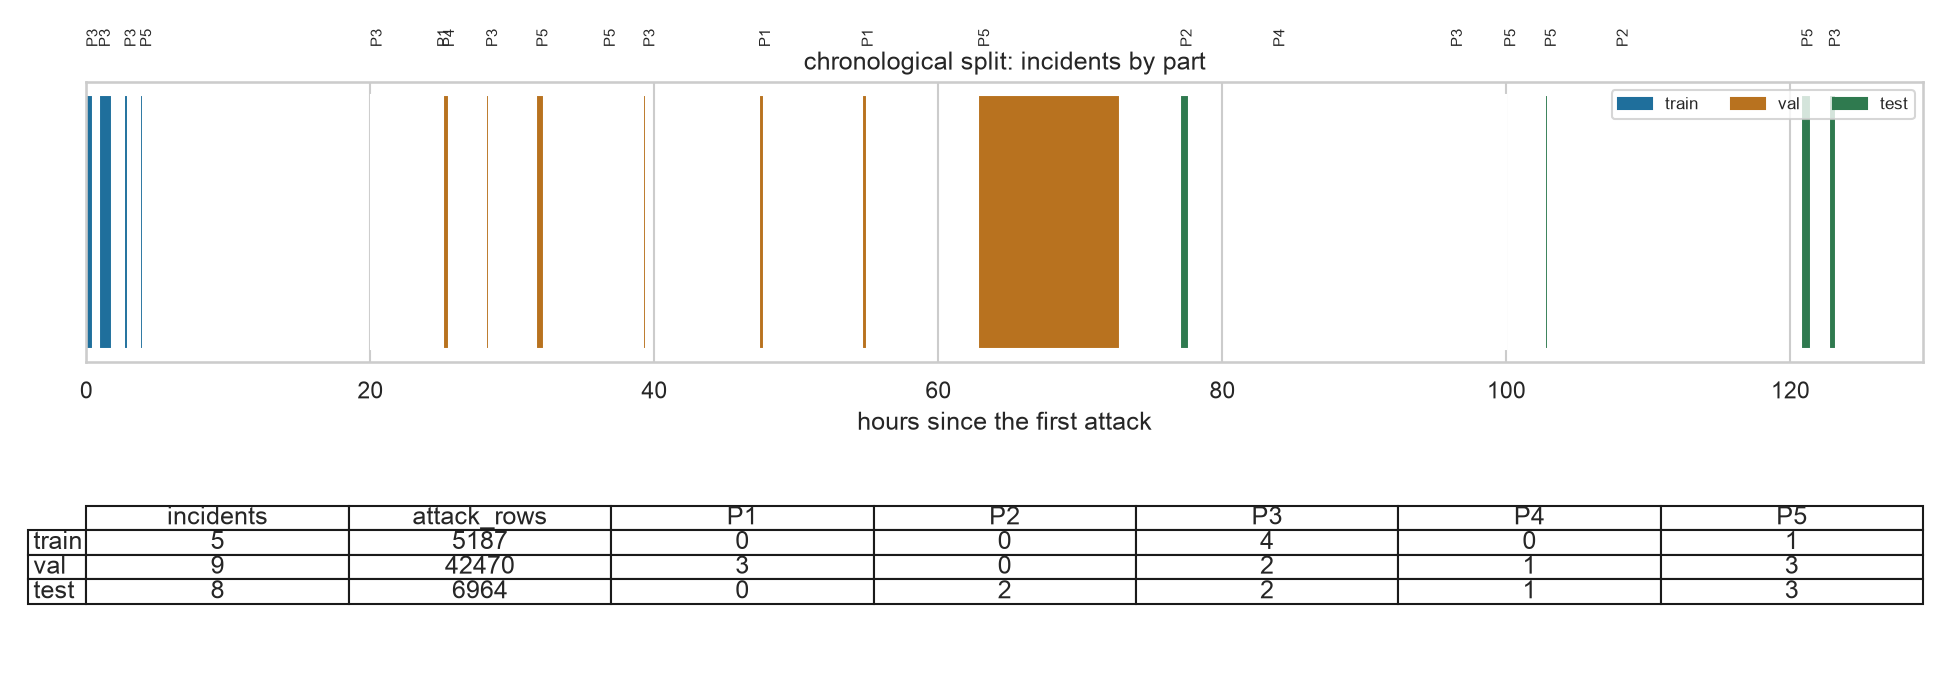

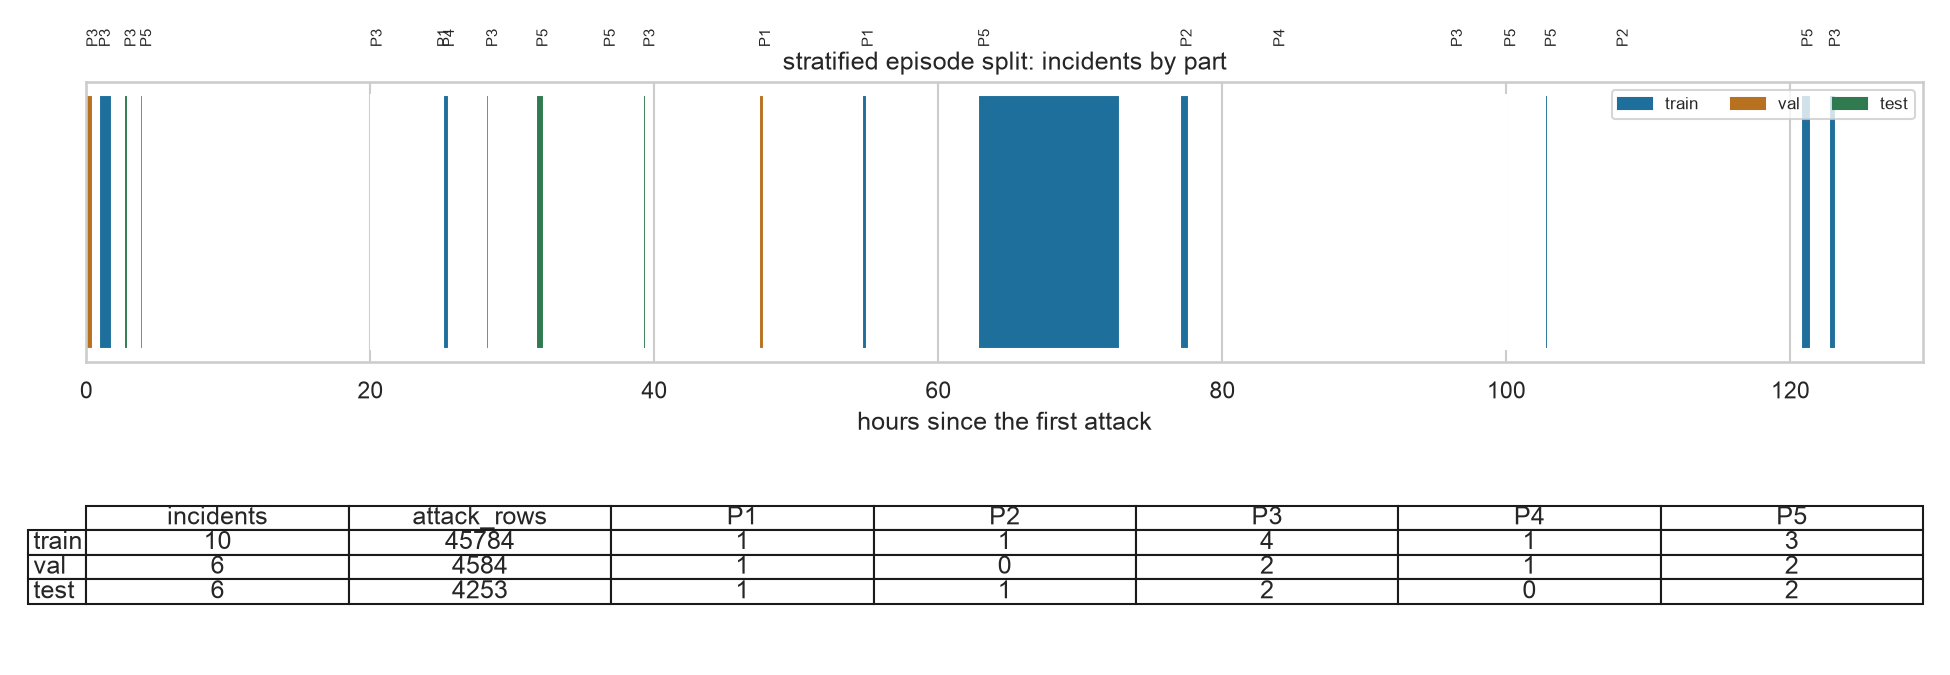

swat: 51 features
  train  555,071 rows  anomaly rate 0.0093
  val    185,024 rows  anomaly rate 0.2295
  test   185,024 rows  anomaly rate 0.0376

swat-stratified: 51 features
  train  708,650 rows  anomaly rate 0.0646
  val    116,159 rows  anomaly rate 0.0395
  test    88,910 rows  anomaly rate 0.0478


In [4]:
inc_chrono = viz.chronological_incidents(df_raw, chrono)
viz.plot_incident_map(inc_chrono, len(df_raw), FIG / "swat-incidents-chrono.png",
                      "chronological split: incidents by part")
viz.plot_incident_map(strat.incidents, len(df_raw), FIG / "swat-incidents-strat.png",
                      "stratified episode split: incidents by part")
display(Image(filename=str(FIG / "swat-incidents-chrono.png")))
display(Image(filename=str(FIG / "swat-incidents-strat.png")))
print(chrono.summary()); print(); print(strat.summary())

**Why not ordinary stratified k-fold?** It shuffles single rows, so second
*t* is in train and second *t+1* in test. The model memorises the
neighbourhood and the score is meaningless. The stratified split here moves
whole incidents (with their normal lead-in and tail-off), keeps time order
inside each part, drops 300 rows either side of every boundary (≥ 5×
`WINDOW_SIZE`, > the longest lag), and windowed models never window across a
join (`Split.continuity_mask`).

**What it costs.** Train now contains normal rows from after some test
blocks, so slow drift is partly learned rather than tested. Keep both
protocols in the report: chronological answers "deployed on day one",
stratified answers "detects each kind of attack once it has seen examples".

## 3. Pearson-based feature selection

Point-biserial |r| with the label, computed on **training rows only**
(full-data |r| of FIT504 is 0.77, but 0.33 on chronological train: the
full-data number is the validation attack leaking in). `relevance="episode"`
gives each attack one vote, so the 10-hour attack does not decide the ranking
alone. The number kept is chosen on **validation** PR-AUC.

In [5]:
from sklearn.metrics import average_precision_score as ap
from models import REGISTRY

rows = []
for rel in ("pooled", "episode"):
    for red in (0.95, 1.01):
        for k in (10, 20, 25, 30, 35, None):
            keep, _ = pearson_select(strat, top_k=k, relevance=rel, max_redundancy=red)
            fs = subset(strat, keep)
            nb = REGISTRY["naive_bayes"]().fit(fs)
            rows.append({"relevance": rel, "prune_redundant": red < 1, "k": k or "all",
                         "n": len(keep), "val_pr_auc_nb": ap(fs.y_val, nb.score(fs.X_val))})
sweep = pd.DataFrame(rows)
nb_all = ap(strat.y_val, REGISTRY["naive_bayes"]().fit(strat).score(strat.X_val))
print(f"Naive Bayes, all 51 features: val PR-AUC {nb_all:.3f}")
sweep.pivot_table(index=["relevance", "prune_redundant"], columns="n", values="val_pr_auc_nb").round(3)

Naive Bayes, all 51 features: val PR-AUC 0.459


n                             10     20     25     27     28     30     35     43
relevance prune_redundant                                                        
episode   False            0.322  0.319  0.346    NaN    NaN  0.489  0.455  0.459
          True             0.325  0.425  0.435  0.373    NaN    NaN    NaN    NaN
pooled    False            0.276  0.316  0.328    NaN    NaN  0.353  0.448  0.459
          True             0.308  0.421  0.440    NaN  0.369    NaN    NaN    NaN

**Reading it.** Removing redundant pairs (|r| > 0.95) *hurts*. Sensors that
move together in normal operation (FIT504 with FIT401, P501 with UV401)
decouple exactly when one of them is spoofed, so dropping one of the pair
removes the attack signal. The useful part of Pearson selection here is
dropping constant sensors and low-relevance noise; the gain is small and
measured on only six validation incidents.

In [ ]:
keep30, table30 = pearson_select(strat, top_k=30, relevance="episode", max_redundancy=1.01)
strat_fs = subset(strat, keep30)
print("kept:", strat_fs.feature_names)
table30.head(35)

kept: ['LIT301', 'AIT503', 'FIT401', 'FIT501', 'LIT101', 'AIT504', 'FIT503', 'AIT201', 'AIT202', 'P203', 'AIT203', 'FIT201', 'FIT504', 'P101', 'P205', 'PIT502', 'PIT503', 'AIT402', 'PIT501', 'FIT101', 'MV101', 'LIT401', 'MV201', 'AIT502', 'P201', 'P102', 'DPIT301', 'FIT502', 'P302', 'FIT301']


,feature,abs_r_label,status,redundant_with
0,LIT301,0.409210,kept,
1,AIT503,0.398310,kept,
2,FIT401,0.342108,kept,
3,FIT501,0.334878,kept,
4,LIT101,0.313481,kept,
5,AIT504,0.297073,kept,
6,FIT503,0.291863,kept,
7,AIT201,0.283726,kept,
8,AIT202,0.278634,kept,
9,P203,0.274672,kept,


: 

## 4. All models, both protocols, both threshold rules

`threshold_mode="percentile"` is the existing rule (97th percentile of
validation-normal scores). It fixes the false-alarm rate at 3%, which on
SWaT's test window is more false alarms than there are attack rows.
`"val_f1"` picks the F1-maximising threshold on validation labels. Both
look only at validation.

In [ ]:
from experiment import run

MODELS = ["random", "naive_bayes", "logistic_regression", "logreg_adam", "mlp_bce",
          "adaboost", "xgboost", "random_forest", "cnn_classifier", "lstm_forecast", "lstm_ae"]
OVERRIDES = {"lstm_forecast": {"train_stride": 5}, "lstm_ae": {"train_stride": 5}}

results = {}
for cname, sp in {"chrono": chrono, "strat": strat, "strat_fs30": strat_fs}.items():
    for mode in ("percentile", "val_f1"):
        models = MODELS if mode == "percentile" else [m for m in MODELS if not m.startswith("lstm")]
        if cname == "strat_fs30":
            models = [m for m in models if m not in ("lstm_ae", "random")]
        results[(cname, mode)] = run(sp, models, tag=f"protocols-{cname}-{mode}",
                                     threshold_mode=mode, overrides=OVERRIDES)

swat: 51 features
  train  555,071 rows  anomaly rate 0.0093
  val    185,024 rows  anomaly rate 0.2295
  test   185,024 rows  anomaly rate 0.0376

  random ...
random on swat
  anomaly rate     0.0376   threshold 0.9698
  ROC-AUC          0.4974    PR-AUC 0.0376
  pointwise      P 0.037  R 0.030  F1 0.033  MCC -0.001
  point-adjusted P 0.564  R 1.000  F1 0.721  MCC 0.740
  F1 inflation     +0.688

  naive_bayes ...
naive_bayes on swat
  anomaly rate     0.0376   threshold 6.083e-22
  ROC-AUC          0.6512    PR-AUC 0.3227
  pointwise      P 0.926  R 0.321  F1 0.476  MCC 0.536
  point-adjusted P 0.932  R 0.350  F1 0.509  MCC 0.563
  F1 inflation     +0.033

  logistic_regression ...
logistic_regression on swat
  anomaly rate     0.0376   threshold 0.9999
  ROC-AUC          0.6520    PR-AUC 0.2891
  pointwise      P 0.269  R 0.338  F1 0.300  MCC 0.271
  point-adjusted P 0.285  R 0.368  F1 0.321  MCC 0.294
  F1 inflation     +0.022

  logreg_adam ...
    epoch   0  train bce 0.7740  va

In [ ]:
table = pd.DataFrame([
    {"config": c, "threshold": m, "model": r.meta["model"], "roc_auc": r.roc_auc,
     "pr_auc": r.pr_auc, "f1_pointwise": r.pointwise.f1, "precision": r.pointwise.precision,
     "recall": r.pointwise.recall, "f1_point_adjust": r.point_adjusted.f1}
    for (c, m), rs in results.items() for r in rs
])
table.pivot_table(index="model", columns=["config", "threshold"], values="f1_pointwise").round(3)

In [ ]:
table.pivot_table(index="model", columns="config", values="pr_auc", aggfunc="first").round(3)

## 5. Training curves: train vs validation

Training loss alone can only show the optimiser works. The validation curve
shows whether that translates into anything; the dashed line marks the epoch
whose weights `_BCETrainer` / `_WindowedMSE` kept.

In [ ]:
from experiment import fit_and_score
diag = {}
for name in ("mlp_bce", "cnn_classifier"):
    det = REGISTRY[name]()
    thr, scores = fit_and_score(strat, det, threshold_mode="val_f1")
    diag[name] = (det, thr, scores)
    p = FIG / f"swat-strat-{name}-trainval.png"
    viz.plot_train_val_loss(det.name, det.loss_history, det.val_loss_history, p,
                            getattr(det, "best_epoch", None), getattr(det, "val_pr_auc", None))
    display(Image(filename=str(p)))

## 6. Which attacks each model actually catches

One column per test incident: the fraction of its attack seconds flagged at
the validation-chosen threshold. An F1 can hide "catches four attacks fully,
misses two entirely"; this table cannot.

In [ ]:
from experiment import best_f1_threshold, score_part
det_rows = {}
for name in ("naive_bayes", "logistic_regression", "adaboost", "xgboost"):
    det = REGISTRY[name]().fit(strat)
    thr = best_f1_threshold(strat.y_val, score_part(det, strat, "val"))
    det_rows[det.name] = viz.per_incident_detection(strat.y_test, score_part(det, strat, "test"), thr)
for name, (det, thr, scores) in diag.items():
    det_rows[det.name] = viz.per_incident_detection(strat.y_test, scores, thr)
heat = pd.DataFrame(det_rows).T
viz.plot_detection_heatmap(heat, FIG / "swat-strat-per-incident.png",
                           "stratified split: fraction of each test incident detected")
display(Image(filename=str(FIG / "swat-strat-per-incident.png")))